# 11/2 tasks: compound stopping (Task A) and 2-D stopping (Task B)

Continues `STA496_OptimalStopping_SmoothMax.ipynb`. Same method: Deep Galerkin, $h=g+k$ with $k=(T-t)\,\mathrm{softplus}(N_\phi)\ge0$, $g_\theta$ frozen, and the **Gaussian** smooth max in the loss.

**Model (from the 11/2 sheet).** $X_t=e^{-\frac12t+W_t}$, i.e. $dX_t=X_t\,dW_t$, $X_0=1$. Generator $\mathcal L=\partial_t+\tfrac12x^2\partial_{xx}$. Value function
$$h(t,x)=\sup_{\tau\in[t,T]}\mathbb E\big[\psi(\tau,X_\tau)\mid X_t=x\big],\qquad \max\{\mathcal Lh,\ \psi-h\}=0,\quad h(T,\cdot)=\psi(T,\cdot).$$

| | obstacle $\psi(t,x)$ |
|---|---|
| **A1** (base problem) | $\big(e^{-rt}-x\big)_+$ |
| **A2** (compound) | $\big(L\,e^{-rt}-h_1(t,x)\big)_+$, $\ h_1$ = solution of A1, $L=0.1$ |
| **B** (2-D, $dY_t=Y_t\,dW^2_t$, $W^1\perp W^2$) | $\big(e^{-rt}-\min(x,y)\big)_+$, $\ \mathcal L=\partial_t+\tfrac12x^2\partial_{xx}+\tfrac12y^2\partial_{yy}$ |

**Choices not on the sheet** (all are parameters below): $T=1$, $r=0.1$. Non-smooth pieces are Gaussian-smoothed exactly as before: $(u)_+\to\mathbb E[(u+\delta Z)_+]=u\Phi(u/\delta)+\delta\phi(u/\delta)$, and $\min(x,y)=-\max(-x,-y)$ with the Gaussian smooth max. Smooth max in the loss: Gaussian, $\varepsilon=0.01$.

**Reference.** Explicit finite differences in $\log x$ (and $\log y$) on the *same smoothed* obstacles, so the comparison measures the network error only.

---
# Derivations

Five results the code relies on. Each is stated first, then proved without skipping steps.

**Must know (for the meeting):**
1. The generator of $dX_t=X_t\,dW_t$ is $\mathcal L=\partial_t+\tfrac12x^2\partial_{xx}$.
2. In $z=\log x$ it becomes $\partial_t-\tfrac12\partial_z+\tfrac12\partial_{zz}$, and on a bounded $z$-interval boundary values are needed.
3. In 2-D with independent Brownian motions there is no $\partial_{xy}$ term.
4. The 2-D stop region lies inside the L-shaped set $\{\min(x,y)\le x_1^*(t)\}$, with equality far from the corner.
5. (optional) Why the compound problem A2 fits the same framework, and why its stop region is at large $x$.

---
## D1. Generator of $dX_t=X_t\,dW_t$ (Itô's formula)

**Itô's formula (1-D).** If $dX_t=\mu_t\,dt+\sigma_t\,dW_t$ and $f(t,x)$ is $C^{1,2}$, then
$$df(t,X_t)=\partial_tf\,dt+\partial_xf\,dX_t+\tfrac12\partial_{xx}f\,(dX_t)^2,\qquad (dt)^2=dt\,dW_t=0,\ (dW_t)^2=dt.$$

**Why the second-order term stays** (discrete picture, as in the 11/1 notes): over a step $\Delta t$, $\Delta W\approx\pm\sqrt{\Delta t}$, so $(\Delta W)^2=\Delta t$ is the same order as $\Delta t$ and cannot be dropped, while $(\Delta t)^2$ and $\Delta t\,\Delta W$ are smaller.

**Step 1: $X$ solves $dX=X\,dW$.** $X_t=f(t,W_t)$ with $f(t,w)=e^{-t/2+w}$: $\partial_tf=-\tfrac12f$, $\partial_wf=f$, $\partial_{ww}f=f$. Itô:
$$dX_t=-\tfrac12X_t\,dt+X_t\,dW_t+\tfrac12X_t\,dt=X_t\,dW_t .$$

**Step 2: apply Itô to $h(t,X_t)$.** $(dX_t)^2=X_t^2(dW_t)^2=X_t^2\,dt$, so
$$dh(t,X_t)=\Big(\partial_th+\tfrac12X_t^2\,\partial_{xx}h\Big)dt+X_t\,\partial_xh\,dW_t .$$
The $dW$ term has mean zero, so $\mathbb E[dh]=\mathcal Lh\,dt$ with $\mathcal L=\partial_t+\tfrac12x^2\partial_{xx}$. This is exactly the previous notebook with $\tfrac12\partial_{xx}$ replaced by $\tfrac12x^2\partial_{xx}$ (there $dX=dW$, so $(dX)^2=dt$).

**Step 3: same variational inequality.** In the continuation region the value must not change on average ($\mathcal Lh=0$); in the stop region $h=\psi$ and waiting cannot help ($\mathcal Lh\le0$). Hence $\max\{\mathcal Lh,\ \psi-h\}=0$, $h(T,\cdot)=\psi(T,\cdot)$.

---
## D2. Log coordinates and why boundary conditions are needed

**Change of variables.** Let $x=e^z$ and $u(t,z)=h(t,e^z)$. Chain rule:
$$u_z=e^z h_x=x\,h_x,\qquad u_{zz}=\partial_z\big(e^zh_x\big)=e^zh_x+e^{2z}h_{xx}=x\,h_x+x^2h_{xx}.$$
So $x^2h_{xx}=u_{zz}-u_z$ and
$$\mathcal L=\partial_t+\tfrac12x^2\partial_{xx}=\partial_t-\tfrac12\partial_z+\tfrac12\partial_{zz}.$$
Check: $Z_t=\log X_t=-\tfrac12t+W_t$ is a Brownian motion with drift $-\tfrac12$, whose generator is exactly $\partial_t-\tfrac12\partial_z+\tfrac12\partial_{zz}$. $\checkmark$

*Why bother:* $x\in(0,\infty)$ is hard to sample (a uniform sample on $[0.02,3]$ misses the tail), while $z\in[\log0.01,\log20]$ is a bounded interval with constant coefficients.

**Why a boundary condition is needed.** On a bounded interval $[z_{lo},z_{hi}]$, the equation $\mathcal Lu=0$ with terminal value $u(T,\cdot)$ has **one solution for every choice of boundary values** $u(t,z_{lo}),u(t,z_{hi})$. The loss only sees the PDE residual at interior points, so it cannot tell these solutions apart. The network can settle on any of them. This is what happened in the first run: no boundary term, and A1 came out about $0.04$ too high everywhere.

**Which boundary values.** Far from the money the value equals the obstacle:
- $x=20$ ($z_{hi}$): reaching $x<1$ by time $T$ needs a drop of $\log 20=3$ standard deviations, probability $\approx0$, so $h\approx0=\psi$.
- $x=0.01$ ($z_{lo}$): $X$ stays far below $e^{-rT}$, and waiting only lowers $e^{-rt}$, so stopping now is optimal: $h=\psi$.

The loss adds $w\cdot\text{mean}\big((h-\psi)^2\big)$ at these boundary points.

---
## D3. Two dimensions: no cross term

**Itô (2-D).**
$$dh(t,X_t,Y_t)=\partial_th\,dt+h_x\,dX+h_y\,dY+\tfrac12h_{xx}(dX)^2+h_{xy}\,dX\,dY+\tfrac12h_{yy}(dY)^2 .$$
- $(dX)^2=X^2dt$, $(dY)^2=Y^2dt$ (as in D1).
- $dX\,dY=XY\,dW^1dW^2=XY\,d\langle W^1,W^2\rangle_t=0$, because $W^1,W^2$ are independent ($\langle W^1,W^2\rangle\equiv0$).

So $\mathcal L=\partial_t+\tfrac12x^2\partial_{xx}+\tfrac12y^2\partial_{yy}$. With correlation $\rho$ there would be an extra $\rho\,xy\,\partial_{xy}$. In log coordinates it is two copies of D2: $\partial_t+\sum_{i}\big(-\tfrac12\partial_{z_i}+\tfrac12\partial_{z_iz_i}\big)$.

**Boundary values in 2-D.** If $x$ is huge, $\min(X_s,Y_s)=Y_s$ for all $s\le T$ with probability $\approx1$, so the problem reduces to A1 in $y$: $h(t,x_{hi},y)\approx h_1(t,y)$. If $x$ is tiny, stop now: $h=\psi$. So **the 1-D solution from A1 is the boundary condition for B.**

---
## D4. The 2-D stop region is L-shaped

Write $h_1$ for the 1-D value (A1) and $x_1^*(t)$ for its boundary: $h_1(t,y)=\psi_1(t,y)\iff y\le x_1^*(t)$.

**Claim.** $\ \{\text{stop in 2-D}\}\subseteq\{(x,y):\min(x,y)\le x_1^*(t)\}$.

*Proof.* Take a point with $y\le x$ (the other case is symmetric).
1. Since $\min(X_s,Y_s)\le Y_s$ for every $s$, the 2-D payoff dominates the 1-D payoff in $Y$: $\big(e^{-rs}-\min(X_s,Y_s)\big)_+\ge\big(e^{-rs}-Y_s\big)_+$. Taking sup over stopping times: $h(t,x,y)\ge h_1(t,y)$.
2. At the point, $\min(x,y)=y$, so $\psi(t,x,y)=\psi_1(t,y)$.
3. If the point is in the 2-D stop region, $h=\psi$, so $\psi_1(t,y)=h(t,x,y)\ge h_1(t,y)\ge\psi_1(t,y)$. Hence $h_1(t,y)=\psi_1(t,y)$, i.e. $\min(x,y)=y\le x_1^*(t)$. $\square$

**Reading the picture.** Far from the corner ($x$ large), D3 gives $h\approx h_1(t,y)$, so the strip has height exactly $x_1^*(t)$ (at $t=0$: $\approx0.27$, matching the 2-D plot). Near the corner both coordinates are small and either one may fall further, so waiting is worth more and the stop region is **strictly thinner** than the L. Both the network and FD show this dip.

---
## D5. (Optional) The compound problem A2

- **Same framework.** The theory only needs a continuous obstacle. $h_1$ is continuous (smooth inside the regions), so $\psi_2=(Le^{-rt}-h_1)_+$ is a valid obstacle and nothing else changes.
- **Terminal condition is explicit.** $h_1(T,x)=\psi_1(T,x)$, so $\psi_2(T,x)=(Le^{-rT}-\psi_1(T,x))_+$ needs no network.
- **Where it stops.** $\psi_2>0\iff h_1<Le^{-rt}$. $h_1$ is decreasing in $x$ (a smaller $x$ gives a larger payoff along every path), so this happens for **large** $x$: stop region $\{x\ge x_2^*(t)\}$.
- **Why it only appears near maturity here.** $h_1(0,1)\approx0.33\gg L=0.1$, so $h_1<0.1$ needs $x$ well above $2.5$ unless $T-t$ is small.

In [1]:
import sys, time, json
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
sys.path.insert(0, ".")
from fd_ref import splus as splus_np, smin as smin_np, fd_1d, fd_1d_full, interp_tx, fd_2d

torch.manual_seed(0)
device = torch.device("cpu")
torch.set_default_dtype(torch.float32)

# ---------------- parameters ----------------
T, r, L = 1.0, 0.1, 0.1
delta   = 0.05     # smoothing of (.)_+ in A1 and B
delta2  = 0.05     # smoothing of (.)_+ in A2
delta_m = 0.05     # smoothing of min(x, y) in B
eps     = 0.01     # Gaussian smooth max in the loss
z_lo, z_hi = np.log(0.01), np.log(20.0)   # we work in z = log x (and log y)
w_bc = 1.0                                 # weight of the boundary penalty
lr = 1e-3

Nd = torch.distributions.Normal(0.0, 1.0)
Phi = Nd.cdf
phi = lambda z: torch.exp(Nd.log_prob(z))

def splus(u, d):                 # E[(u + d Z)_+]
    z = u / d
    return u * Phi(z) + d * phi(z)

def smax(a, b, e):               # Gaussian smooth max E[max(a + e Z, b)]
    z = (a - b) / e
    return a * Phi(z) + b * Phi(-z) + e * phi(z)

def smin(a, b, e): return -smax(-a, -b, e)

## Networks, generator, training

Same structure as the previous notebook. Two changes, both forced by the geometric dynamics:

1. **Work in $z=\log x$.** With $x=e^z$, $\tfrac12x^2\partial_{xx}=\tfrac12(\partial_{zz}-\partial_z)$, so the generator is $\partial_t-\tfrac12\partial_z+\tfrac12\partial_{zz}$ (one copy per space variable). The network sees $(t,z)$; $x$ only enters through $\psi$. We sample $z\sim U[\log 0.01,\log 20]$.
2. **Boundary penalty.** On a bounded $z$-interval the PDE alone does not pin down the solution: the first run (sampling $x\in[0.02,3]$ with no boundary condition) came out about $0.04$ too high everywhere for A1 and badly off for A2. Fix: add $w\cdot\text{mean}\big((f-\text{target})^2\big)$ at $z=z_{lo},z_{hi}$. In 1-D the target is the obstacle (far out of / deep in the money the value is the obstacle). In 2-D, if $x$ is huge then $\min(x,y)=y$, so the target is the **1-D solution from A1** in the other variable.

In [2]:
class MLP(nn.Module):
    def __init__(self, d_in, hidden=64, n_hidden=3):
        super().__init__()
        layers = [nn.Linear(d_in, hidden), nn.Tanh()]
        for _ in range(n_hidden - 1):
            layers += [nn.Linear(hidden, hidden), nn.Tanh()]
        layers += [nn.Linear(hidden, 1)]
        self.net = nn.Sequential(*layers)
    def forward(self, *z):
        return self.net(torch.cat(z, dim=1))

class GNet(nn.Module):           # g = psi(T, .) + (T - t) N_theta   (exact terminal condition)
    def __init__(self, psiT, d):
        super().__init__(); self.psiT = psiT; self.N = MLP(1 + d)
    def forward(self, t, *s):
        return self.psiT(*s) + (T - t) * self.N(t, *s)

class HNet(nn.Module):           # h = g (frozen) + (T - t) softplus(N_phi)
    def __init__(self, g, d):
        super().__init__(); self.g = g; self.K = MLP(1 + d)
    def k(self, t, *s):
        return (T - t) * nn.functional.softplus(self.K(t, *s))
    def forward(self, t, *s):
        return self.g(t, *s) + self.k(t, *s)

def generator(fn, t, *z):
    # returns f and (d_t + sum_i [-1/2 d_{z_i} + 1/2 d_{z_i z_i}]) f, for any number of log-space variables
    t = t.detach().requires_grad_(True)
    z = [v.detach().requires_grad_(True) for v in z]
    f = fn(t, *z)
    ones = torch.ones_like(f)
    out = torch.autograd.grad(f, t, ones, create_graph=True)[0]
    for v in z:
        fv = torch.autograd.grad(f, v, ones, create_graph=True)[0]
        fvv = torch.autograd.grad(fv, v, torch.ones_like(fv), create_graph=True)[0]
        out = out - 0.5 * fv + 0.5 * fvv
    return f, z, out

def sample(n, d):
    t = T * torch.rand(n, 1)
    z = [z_lo + (z_hi - z_lo) * torch.rand(n, 1) for _ in range(d)]
    return t, z

def sample_bd(n, d):
    # points on the boundary: one coordinate set to z_lo or z_hi, the others uniform
    t, z = sample(n, d)
    k = torch.randint(0, d, (n,))
    side = torch.where(torch.rand(n, 1) < 0.5, torch.tensor(z_lo, dtype=torch.float32), torch.tensor(z_hi, dtype=torch.float32))
    z = [torch.where((k == i).reshape(-1, 1), side, v) for i, v in enumerate(z)]
    return t, z

def freeze(m):
    for p in m.parameters(): p.requires_grad_(False)
    return m

def train_g(psiT, d, n_iter, bc, batch=1024, seed=1):
    torch.manual_seed(seed)
    m = GNet(psiT, d); opt = torch.optim.Adam(m.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.StepLR(opt, max(1, n_iter // 3), 0.3); hist = []
    for _ in range(n_iter):
        t, s = sample(batch, d)
        _, _, res = generator(m, t, *s)
        tb_, zb = sample_bd(256, d)
        loss = (res ** 2).mean() + w_bc * ((m(tb_, *zb) - bc(tb_, *zb)) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sch.step(); hist.append(loss.item())
    return freeze(m), hist

def train_h(g, psi, d, n_iter, bc, batch=512, seed=2):
    torch.manual_seed(seed)
    m = HNet(g, d); opt = torch.optim.Adam(m.K.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.StepLR(opt, max(1, n_iter // 3), 0.3); hist = []
    for _ in range(n_iter):
        t, s = sample(batch, d)
        h, sg, a = generator(m, t, *s)            # a = L h
        b = psi(t, *sg) - h                       # b = psi - h
        tb_, zb = sample_bd(256, d)
        loss = (smax(a, b, eps) ** 2).mean() + w_bc * ((m(tb_, *zb) - bc(tb_, *zb)) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sch.step(); hist.append(loss.item())
    return freeze(m), hist

def ev(fn, t, *x):
    # evaluate a network at (t, x...) given in ORIGINAL x-units (converts to z = log x)
    with torch.no_grad():
        args = [torch.as_tensor(np.asarray(t, dtype=np.float32)).reshape(-1, 1)]
        args += [torch.log(torch.as_tensor(np.asarray(v, dtype=np.float32)).reshape(-1, 1)) for v in x]
        return fn(*args).numpy().ravel()

---
# Task A1: base problem $\psi_1=(e^{-rt}-x)_+$

In [3]:
# all torch functions below take z = log x
psi1  = lambda t, z: splus(torch.exp(-r * t) - torch.exp(z), delta)
psi1T = lambda z: psi1(torch.full_like(z, T), z)
psi1_np = lambda t, x: splus_np(np.exp(-r * t) - x, delta)

t0 = time.time()
g1, hg1 = train_g(psi1T, 1, n_iter=4000, bc=lambda t, z: psi1T(z))
h1, hh1 = train_h(g1, psi1, 1, n_iter=20000, bc=psi1)
print(f"A1 trained in {time.time()-t0:.0f}s | final losses g {np.mean(hg1[-100:]):.1e}, h {np.mean(hh1[-100:]):.1e}")

# FD reference on a full time grid (also needed as the obstacle of A2)
xf, tsf, U1 = fd_1d_full(psi1_np, T=T, dy=0.01)
h1_ref = interp_tx(xf, tsf, U1)
_, oe = fd_1d(psi1_np, T=T, dy=0.01, save_times=(0.0,), stopping=False)
print(f"FD: h1(0,1) = {h1_ref(0.0, 1.0):.4f}, European g1(0,1) = {np.interp(1.0, xf, oe[0.0]):.4f}, DGM h1(0,1) = {ev(h1, 0.0, 1.0)[0]:.4f}")

A1 trained in 390s | final losses g 1.6e-03, h 2.9e-05


FD: h1(0,1) = 0.3336, European g1(0,1) = 0.3193, DGM h1(0,1) = 0.3394


---
# Task A2: compound problem $\psi_2=(L e^{-rt}-h_1(t,x))_+$

$h_1$ is the **frozen** network from A1. At $t=T$, $h_1(T,x)=\psi_1(T,x)$ exactly (hard constraint), so the terminal condition of $g_2$ is the closed form $\psi_2(T,x)=(Le^{-rT}-\psi_1(T,x))_+$ and $g_2$ needs no network inside its terminal condition. Inside the loss, $b=\psi_2(t,x)-h_2$ calls the network $h_1$.

The FD reference does the same thing with the FD $h_1$ as obstacle.

In [4]:
psi2  = lambda t, z: splus(L * torch.exp(-r * t) - h1(t, z), delta2)
psi2T = lambda z: splus(L * np.exp(-r * T) - psi1T(z), delta2)
psi2_np = lambda t, x: splus_np(L * np.exp(-r * t) - h1_ref(t, x), delta2)

t0 = time.time()
g2, hg2 = train_g(psi2T, 1, n_iter=8000, bc=lambda t, z: psi2T(z), seed=3)
h2, hh2 = train_h(g2, psi2, 1, n_iter=20000, bc=psi2, seed=4)
print(f"A2 trained in {time.time()-t0:.0f}s | final losses g {np.mean(hg2[-100:]):.1e}, h {np.mean(hh2[-100:]):.1e}")

t_show = (0.0, 0.5, 0.9)
xf2, out2 = fd_1d(psi2_np, T=T, dy=0.01, save_times=t_show)
h2_ref = lambda tv, x: np.interp(x, xf2, out2[tv])

A2 trained in 417s | final losses g 1.1e-03, h 6.5e-05


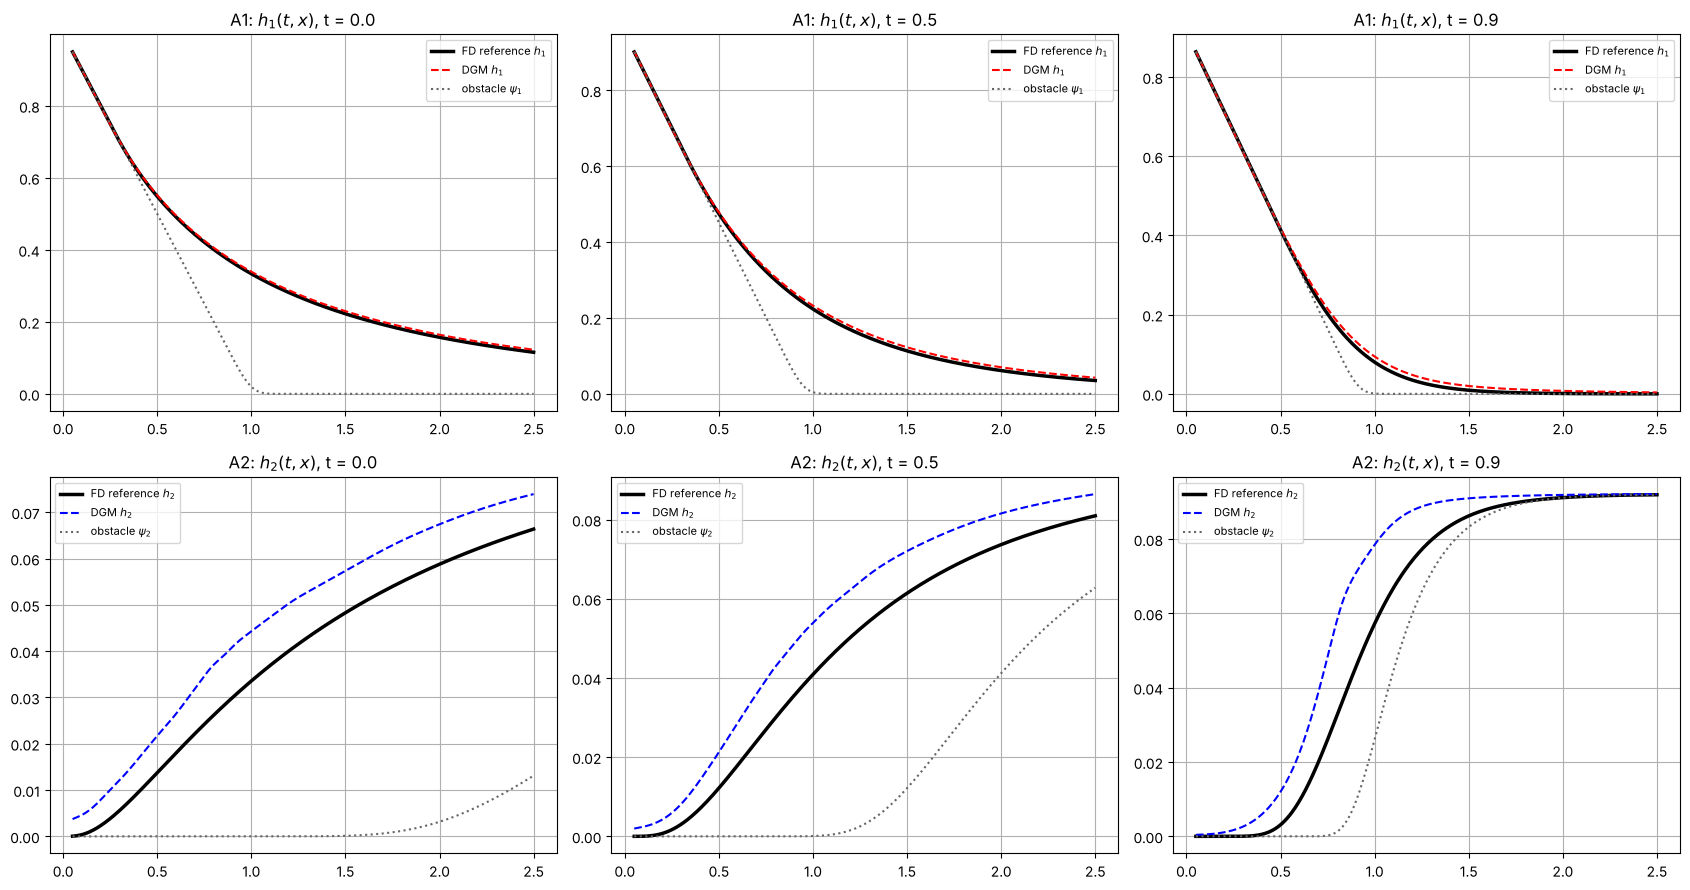

max |DGM - FD| on x in [0.05, 2.5]:
  t=0.0:  A1 0.0074   A2 0.0110
  t=0.5:  A1 0.0096   A2 0.0132
  t=0.9:  A1 0.0144   A2 0.0267


In [5]:
xs = np.linspace(0.05, 2.5, 400)
def stop_boundary(vals, obst, xs, tol):       # stop region = {h - psi < tol}
    return xs[(vals - obst) < tol]

rows = []
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for c, tv in enumerate(t_show):
    tt = np.full_like(xs, tv)
    # A1
    ax = axes[0, c]
    ax.plot(xs, h1_ref(tv, xs), "k-", lw=2.5, label="FD reference $h_1$")
    ax.plot(xs, ev(h1, tt, xs), "r--", label="DGM $h_1$")
    ax.plot(xs, psi1_np(tv, xs), ":", color="0.4", label=r"obstacle $\psi_1$")
    ax.set_title(f"A1: $h_1(t,x)$, t = {tv}"); ax.grid(True); ax.legend(fontsize=8)
    # A2
    ax = axes[1, c]
    ax.plot(xs, h2_ref(tv, xs), "k-", lw=2.5, label="FD reference $h_2$")
    ax.plot(xs, ev(h2, tt, xs), "b--", label="DGM $h_2$")
    ax.plot(xs, psi2_np(tv, xs), ":", color="0.4", label=r"obstacle $\psi_2$")
    ax.set_title(f"A2: $h_2(t,x)$, t = {tv}"); ax.grid(True); ax.legend(fontsize=8)
    e1 = np.abs(ev(h1, tt, xs) - h1_ref(tv, xs)).max(); e2 = np.abs(ev(h2, tt, xs) - h2_ref(tv, xs)).max()
    rows.append((tv, e1, e2))
plt.tight_layout(); plt.savefig("fig_A_values.png", dpi=130); plt.show()
print("max |DGM - FD| on x in [0.05, 2.5]:")
for tv, e1, e2 in rows: print(f"  t={tv:.1f}:  A1 {e1:.4f}   A2 {e2:.4f}")

### Stopping boundaries of $h_1$ and $h_2$

Stop region $=\{x:\ h(t,x)=\psi(t,x)\}$. For the network we use $h-\psi<\text{tol}$ (tol $=5\times10^{-3}$), because the $\varepsilon$-smoothing makes $h_\phi$ sit slightly above $\psi$.

- A1: stop when $x$ is **small** (deep in the money): region $\{x\le x_1^*(t)\}$.
- A2: $\psi_2>0$ only where $h_1<Le^{-rt}$, i.e. where $x$ is **large**; so the stop region is $\{x\ge x_2^*(t)\}$.

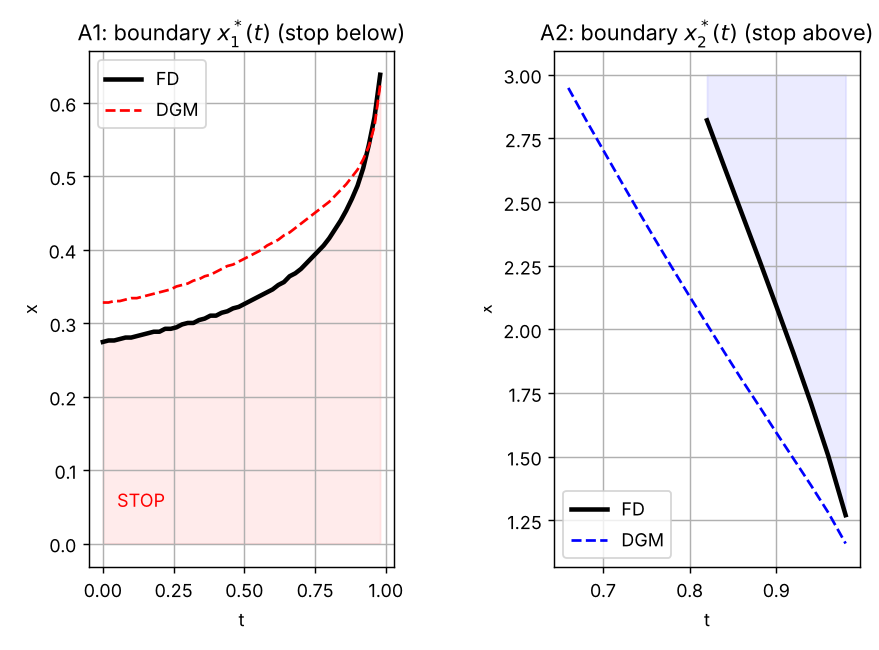

x1*(0): FD 0.274, DGM 0.328 | x2*(0): FD nan, DGM nan


In [6]:
tb = np.linspace(0.0, 0.98, 50)
xs_b = np.linspace(0.02, 3.0, 1500)
def boundaries(val_fn, obst_fn, side, tol):
    out = []
    for tv in tb:
        tt = np.full_like(xs_b, tv)
        stop = (val_fn(tt, xs_b) - obst_fn(tv, xs_b)) < tol
        pos = obst_fn(tv, xs_b) > 1e-3                 # only where the obstacle is actually positive
        sel = xs_b[stop & pos]
        out.append((sel.max() if side == "low" else sel.min()) if len(sel) else np.nan)
    return np.array(out)

# FD boundaries (need FD values on these times)
xr1, o1 = fd_1d(psi1_np, T=T, dy=0.01, save_times=tuple(tb))
xr2, o2 = fd_1d(psi2_np, T=T, dy=0.01, save_times=tuple(tb))
fd1 = lambda tt, x: np.interp(x, xr1, o1[tt[0]]); fd2 = lambda tt, x: np.interp(x, xr2, o2[tt[0]])

b1_fd  = boundaries(fd1, psi1_np, "low", 1e-6);  b1_nn = boundaries(lambda tt, x: ev(h1, tt, x), psi1_np, "low", 5e-3)
b2_fd  = boundaries(fd2, psi2_np, "high", 1e-6); b2_nn = boundaries(lambda tt, x: ev(h2, tt, x), psi2_np, "high", 5e-3)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(tb, b1_fd, "k-", lw=2.5, label="FD"); ax[0].plot(tb, b1_nn, "r--", label="DGM")
ax[0].fill_between(tb, 0, b1_fd, color="r", alpha=0.08); ax[0].text(0.05, 0.05, "STOP", color="r", transform=ax[0].transAxes)
ax[0].set_title(r"A1: boundary $x_1^*(t)$ (stop below)"); ax[0].set_xlabel("t"); ax[0].set_ylabel("x"); ax[0].grid(True); ax[0].legend()
ax[1].plot(tb, b2_fd, "k-", lw=2.5, label="FD"); ax[1].plot(tb, b2_nn, "b--", label="DGM")
ax[1].fill_between(tb, b2_fd, 3.0, color="b", alpha=0.08); ax[1].text(0.9, 0.9, "STOP", color="b", transform=ax[1].transAxes)
ax[1].set_title(r"A2: boundary $x_2^*(t)$ (stop above)"); ax[1].set_xlabel("t"); ax[1].set_ylabel("x"); ax[1].grid(True); ax[1].legend()
plt.tight_layout(); plt.savefig("fig_A_boundaries.png", dpi=130); plt.show()
print("x1*(0): FD %.3f, DGM %.3f | x2*(0): FD %.3f, DGM %.3f" % (b1_fd[0], b1_nn[0], b2_fd[0], b2_nn[0]))

---
# Task B: two dimensions, $\psi=(e^{-rt}-\min(x,y))_+$

Network input is now $(t,x,y)$; the generator adds $\tfrac12y^2\partial_{yy}$ (no cross term because $W^1\perp W^2$). Two non-smooth pieces, both Gaussian-smoothed: $(\cdot)_+$ with $\delta$ and $\min$ with $\delta_m$.

In [7]:
psiB  = lambda t, u, v: splus(torch.exp(-r * t) - smin(torch.exp(u), torch.exp(v), delta_m), delta)
psiBT = lambda u, v: psiB(torch.full_like(u, T), u, v)

def bc_2d(f1d, f2d):
    # x (or y) tiny -> stop / obstacle; x huge -> min(x,y) = y -> 1-D solution in y (and vice versa)
    def target(t, u, v):
        lo = (u <= z_lo + 1e-6) | (v <= z_lo + 1e-6)
        out = torch.where(u >= z_hi - 1e-6, f1d(t, v), f1d(t, u))
        return torch.where(lo, f2d(t, u, v), out)
    return target
psiB_np = lambda t, x, y: splus_np(np.exp(-r * t) - smin_np(x, y, delta_m), delta)

t0 = time.time()
g3, hg3 = train_g(psiBT, 2, n_iter=6000, bc=bc_2d(g1, lambda t, u, v: psiBT(u, v)), seed=5)
print(f"B: g trained in {time.time()-t0:.0f}s, final loss {np.mean(hg3[-100:]):.1e}", flush=True)
t0 = time.time()
h3, hh3 = train_h(g3, psiB, 2, n_iter=20000, bc=bc_2d(h1, psiB), seed=6)
print(f"B: h trained in {time.time()-t0:.0f}s, final loss {np.mean(hh3[-100:]):.1e}")

t0 = time.time()
gB, outB = fd_2d(psiB_np, T=T, dy=0.025, save_times=(0.0, 0.5))
print(f"2-D FD reference in {time.time()-t0:.0f}s")

B: g trained in 134s, final loss 4.7e-03


B: h trained in 841s, final loss 5.2e-04


2-D FD reference in 104s


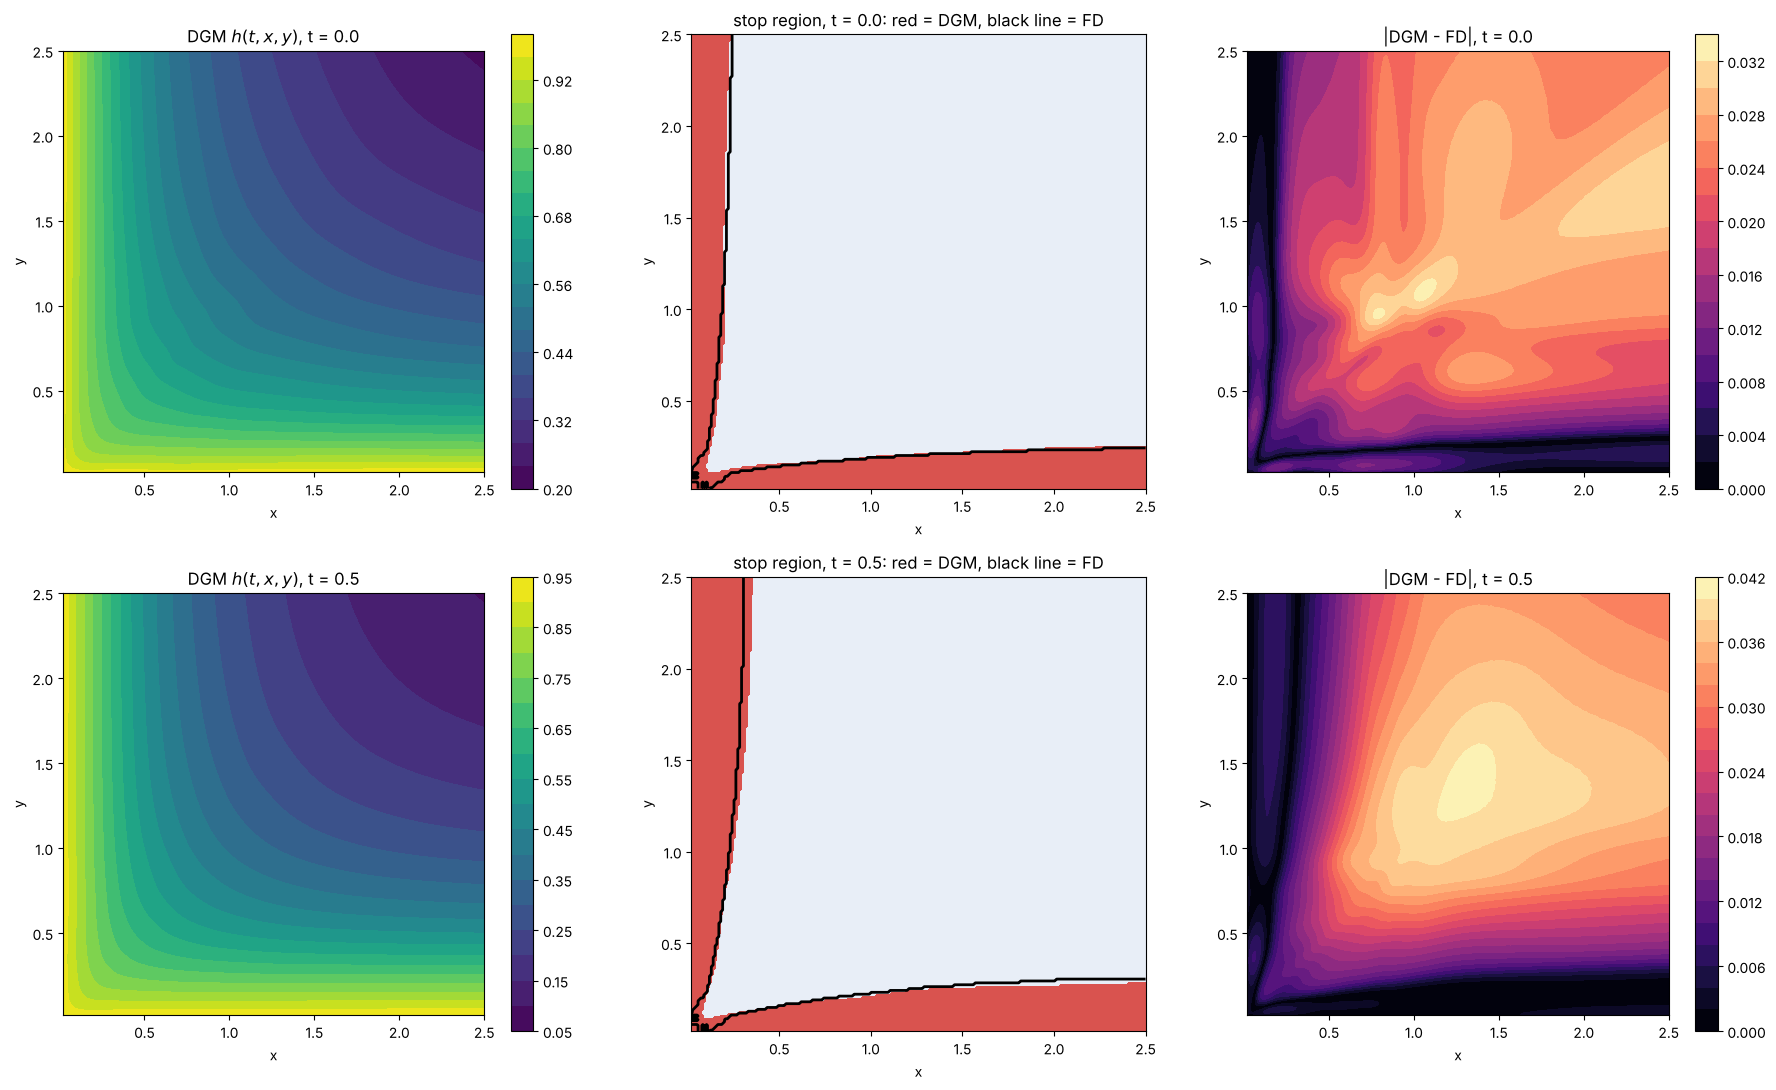

t=0.0: max|DGM-FD| = 0.0329, stop/continue disagree on 1.25% of grid
t=0.5: max|DGM-FD| = 0.0410, stop/continue disagree on 1.86% of grid


In [8]:
n = 241
xg = np.linspace(0.02, 2.5, n); XX, YY = np.meshgrid(xg, xg, indexing="ij")
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
errs = {}
for r_, tv in enumerate((0.0, 0.5)):
    tt = np.full(XX.size, tv)
    H_nn = ev(h3, tt, XX.ravel(), YY.ravel()).reshape(n, n)
    P = psiB_np(tv, XX, YY)
    from scipy.interpolate import RegularGridInterpolator
    fdi = RegularGridInterpolator((gB, gB), outB[tv])
    H_fd = fdi(np.stack([XX.ravel(), YY.ravel()], 1)).reshape(n, n)
    stop_nn = ((H_nn - P) < 5e-3) & (P > 1e-3)
    stop_fd = ((H_fd - P) < 1e-6) & (P > 1e-3)
    errs[tv] = (np.abs(H_nn - H_fd).max(), (stop_nn != stop_fd).mean())

    ax = axes[r_, 0]
    cs = ax.contourf(XX, YY, H_nn, 20, cmap="viridis"); plt.colorbar(cs, ax=ax)
    ax.set_title(f"DGM $h(t,x,y)$, t = {tv}")
    ax = axes[r_, 1]
    ax.contourf(XX, YY, stop_nn.astype(float), levels=[-0.5, 0.5, 1.5], colors=["#e8eef7", "#d9534f"])
    ax.contour(XX, YY, stop_fd.astype(float), levels=[0.5], colors="k", linewidths=2)
    ax.set_title(f"stop region, t = {tv}: red = DGM, black line = FD")
    ax = axes[r_, 2]
    cs = ax.contourf(XX, YY, np.abs(H_nn - H_fd), 20, cmap="magma"); plt.colorbar(cs, ax=ax)
    ax.set_title(f"|DGM - FD|, t = {tv}")
    for a in axes[r_]: a.set_xlabel("x"); a.set_ylabel("y"); a.set_aspect("equal")
plt.tight_layout(); plt.savefig("fig_B_2d.png", dpi=130); plt.show()
for tv, (e, m) in errs.items(): print(f"t={tv}: max|DGM-FD| = {e:.4f}, stop/continue disagree on {100*m:.2f}% of grid")

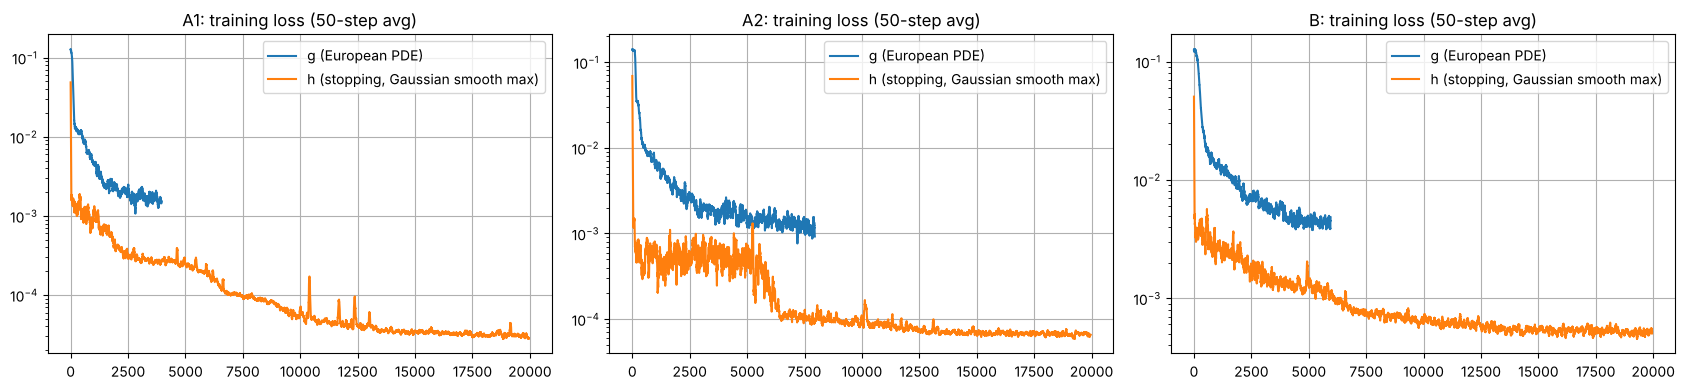

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, (nm, hg, hh) in zip(ax, [("A1", hg1, hh1), ("A2", hg2, hh2), ("B", hg3, hh3)]):
    sm = lambda v: np.convolve(v, np.ones(50) / 50, mode="valid")
    a.semilogy(sm(hg), label="g (European PDE)"); a.semilogy(sm(hh), label="h (stopping, Gaussian smooth max)")
    a.set_title(f"{nm}: training loss (50-step avg)"); a.grid(True); a.legend()
plt.tight_layout(); plt.savefig("fig_losses.png", dpi=130); plt.show()

---
# Summary

**1. Two changes were needed for geometric dynamics.** (i) Work in $z=\log x$, generator $\partial_t-\tfrac12\partial_z+\tfrac12\partial_{zz}$. (ii) Add a boundary penalty: a first run on $x\in[0.02,3]$ with no boundary condition was about $0.04$ too high everywhere in A1, because on a bounded interval the PDE alone does not determine the solution. In 2-D the natural boundary condition at $x=\infty$ is the **1-D solution of A1** in $y$ (since $\min(x,y)=y$), so A1 feeds into B.

**2. A1 (base problem).** Max error vs FD $\approx0.007$–$0.015$; $h_1(0,1)\approx0.34$ (FD $0.334$, European $0.319$, so early-stopping premium $\approx0.015$). Stop region $\{x\le x_1^*(t)\}$ with $x_1^*(0)\approx0.27$, rising towards maturity.

**3. A2 (compound, $\psi_2=(Le^{-rt}-h_1)_+$, $L=0.1$).** The shape is right; error $\approx0.01$–$0.03$ on values up to $0.09$. Part of the error is inherited: $\psi_2$ contains the network $h_1$, so any error in $h_1$ shifts the obstacle one-for-one. With $T=1$ and unit volatility, $h_1(0,1)\approx0.33$, not $0.1$, so $L=0.1$ is small relative to $h_1$: the stop region $\{x\ge x_2^*(t)\}$ only appears close to maturity ($t\gtrsim0.8$ inside $x\le3$).

**4. Smoothing vs training.** Hard max and Gaussian smooth max ($\varepsilon=0.01$) gave the same error on A1, and doubling the number of steps halved it. So at $\varepsilon=0.01$ the remaining error is optimisation error, not regularisation bias.

**5. B (2-D, $\psi=(e^{-rt}-\min(x,y))_+$).** The stop region is **L-shaped**: stop as soon as either coordinate is small enough. It is thicker at $t=0.5$ than at $t=0$. DGM and FD agree on stop/continue at about $98$–$99\%$ of grid points (disagreements only along the boundary); max value error $\approx0.03$–$0.04$ on values in $[0.2,1]$.

### Questions for the meeting
1. Where does $L=0.1$ come from? With $T=1$, $\sigma=1$, $h_1(0,1)\approx0.33$. Should $L$ be scaled to $h_1(0,1)$, or $T$ / volatility be smaller?
2. What are $T$ and $r$ meant to be? (Used $T=1$, $r=0.1$.)
3. For the 2-D picture, is the stop region what you wanted, or the level sets of $h$?